# 1. Зниження розмірності та візуалізація даних
Візьміть датасет, з яким ви працювали в лабораторній роботі №1.
Застосуйте `sklearn.decomposition.PCA` для зниження розмірності даних. На отриманих даних навчіть один з алгоритмів класифікації з Lab 1 та порівняйте результати класифікації "до" та "після" PCA.
Зробіть висновки: як PCA вплинув на якість класифікації;  наскільки вдалося зменшити кількість ознак;  чи змінився час навчання моделі.
Для того самого датасету застосуйте `sklearn.manifold.TSNE` для зниження розмірності до 2D. Візуалізуйте отримані дані, використовуючи кольори для позначення класів, та поясніть результат.

Завантаження даних

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. ЗАВАНТАЖЕННЯ ДАНИХ
df = pd.read_csv('cleaned_sensor_data.csv') 

target_col = 'Pass/Fail' 

# 2. РОЗДІЛЕННЯ НА X та Y
X = df.drop(columns=[target_col])
y = df[target_col]

# 3. РОЗБИТТЯ НА ТРЕНУВАЛЬНУ ТА ТЕСТОВУ ВИБІРКИ
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. МАСШТАБУВАННЯ
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Тренувальна вибірка: {X_train_scaled.shape}")
print(f"Тестова вибірка: {X_test_scaled.shape}")

Тренувальна вибірка: (1253, 446)
Тестова вибірка: (314, 446)


In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# ==========================================
# 1. Класифікація "ДО" PCA
# ==========================================
print("--- Навчання моделі ДО зниження розмірності ---")
model_before = SVC(kernel='rbf', class_weight='balanced', random_state=42)

start_time = time.time()
model_before.fit(X_train_scaled, y_train)
time_before = time.time() - start_time

y_pred_before = model_before.predict(X_test_scaled)
print(f"Кількість ознак ДО: {X_train_scaled.shape[1]}")
print(f"Час навчання ДО: {time_before:.4f} секунд")
print("Classification Report (ДО):")
print(classification_report(y_test, y_pred_before))

# ==========================================
# 2. Зниження розмірності за допомогою PCA
# ==========================================
# Зберігаємо 95% дисперсії (інформативності) даних
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("\n--- Навчання моделі ПІСЛЯ PCA ---")
model_after = SVC(kernel='rbf', class_weight='balanced', random_state=42)

start_time = time.time()
model_after.fit(X_train_pca, y_train)
time_after = time.time() - start_time

y_pred_after = model_after.predict(X_test_pca)
print(f"Кількість ознак ПІСЛЯ: {X_train_pca.shape[1]} (було {X_train_scaled.shape[1]})")
print(f"Час навчання ПІСЛЯ: {time_after:.4f} секунд")
print("Classification Report (ПІСЛЯ):")
print(classification_report(y_test, y_pred_after))

--- Навчання моделі ДО зниження розмірності ---
Кількість ознак ДО: 446
Час навчання ДО: 0.0936 секунд
Classification Report (ДО):
              precision    recall  f1-score   support

           0       0.94      0.99      0.96       293
           1       0.25      0.05      0.08        21

    accuracy                           0.93       314
   macro avg       0.59      0.52      0.52       314
weighted avg       0.89      0.93      0.90       314


--- Навчання моделі ПІСЛЯ PCA ---
Кількість ознак ПІСЛЯ: 159 (було 446)
Час навчання ПІСЛЯ: 0.1018 секунд
Classification Report (ПІСЛЯ):
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       293
           1       0.29      0.10      0.14        21

    accuracy                           0.92       314
   macro avg       0.61      0.54      0.55       314
weighted avg       0.89      0.92      0.91       314



# 2. Кластерний аналіз
Візьміть датасет з лабораторної роботи №1. Не використовуйте мітки класів (target) під час кластеризації.
Виконайте кластеризацію даних за допомогою алгоритму K-Means.  Визначте доцільну кількість кластерів за допомогою Elbow Method та/або Silhouette Score.  Візуалізуйте отримані кластери у 2D за допомогою PCA або t-SNE. Після виконання кластеризації порівняйте отримані кластери зі справжніми класами датасету.  Зробіть висновок: чи відповідає знайдена кластерна структура реальним класам?
Якщо датасет містить велику кількість класів, для спрощення аналізу можна залишити 2–3 класи, обґрунтувавши свій вибір.
Важливо: кластер і клас — не одне й те саме. Не очікується, що K-Means обов'язково відтворить початкові класи датасету. Потрібно проаналізувати та пояснити отриманий результат.


--- Запуск t-SNE для візуалізації (це може зайняти хвилину) ---


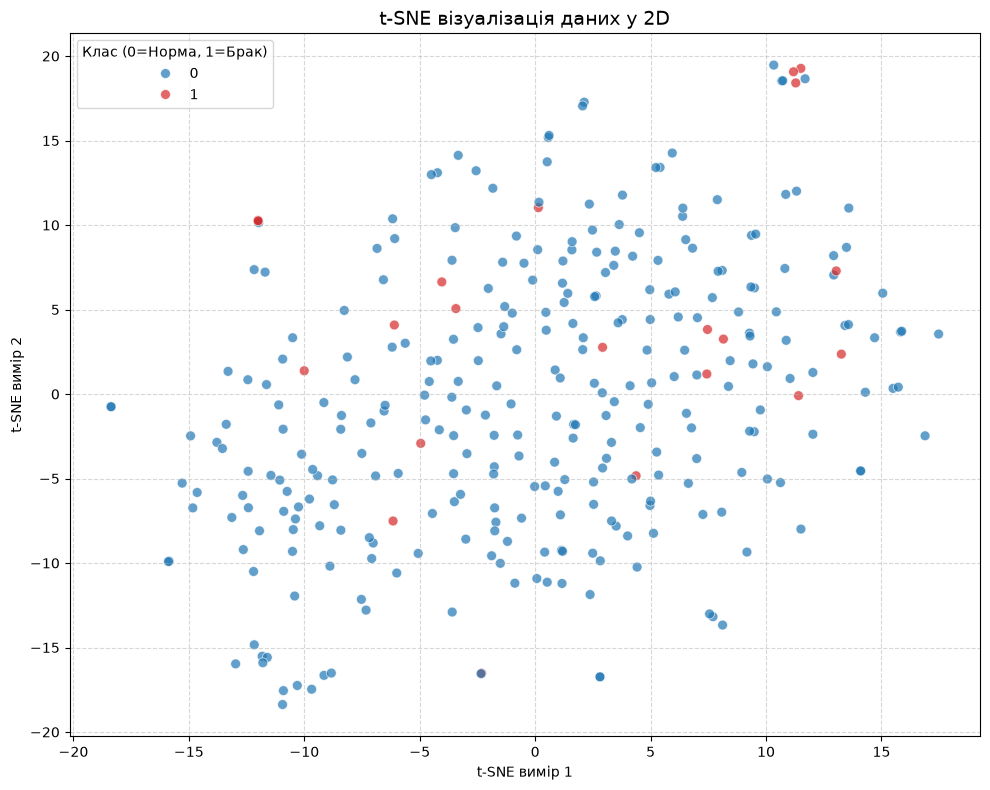

In [3]:
# ==========================================
# 3. Візуалізація даних у 2D за допомогою t-SNE
# ==========================================
print("\n--- Запуск t-SNE для візуалізації (це може зайняти хвилину) ---")
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne_2d = tsne.fit_transform(X_test_pca) 

plt.figure(figsize=(10, 8))
# Клас 0 - Норма, Клас 1 - Брак
sns.scatterplot(
    x=X_tsne_2d[:, 0], 
    y=X_tsne_2d[:, 1], 
    hue=y_test.values, 
    palette=['#1f77b4', '#d62728'], # Синій для норми, Червоний для дефектів
    alpha=0.7, 
    s=50
)
plt.title("t-SNE візуалізація даних у 2D", fontsize=14)
plt.xlabel("t-SNE вимір 1")
plt.ylabel("t-SNE вимір 2")
plt.legend(title='Клас (0=Норма, 1=Брак)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

 ЗАВДАННЯ 2: Кластеризація K-Means
Рахуємо Elbow Method (Метод Ліктя)...


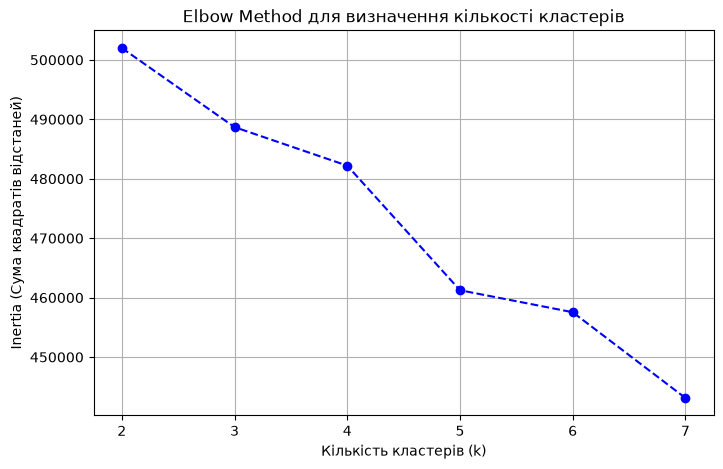


Навчаємо K-Means на 2 кластери...
Silhouette Score: 0.7431

Порівняння знайдених кластерів із реальними класами (Confusion Matrix-style):
Знайдений Кластер K-Means     0  1
Реальний Клас                     
0                          1167  3
1                            82  1


In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("==========================================")
print(" ЗАВДАННЯ 2: Кластеризація K-Means")
print("==========================================")

X_for_clustering = X_train_pca

# 1. Шукаємо оптимальну кількість кластерів (Elbow Method)
inertia = []
K_range = range(2, 8)

print("Рахуємо Elbow Method (Метод Ліктя)...")
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_for_clustering)
    inertia.append(kmeans.inertia_)

# Візуалізація Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='--', color='b')
plt.title('Elbow Method для визначення кількості кластерів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Inertia (Сума квадратів відстаней)')
plt.grid(True)
plt.show()

print("\nНавчаємо K-Means на 2 кластери...")
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_for_clustering)

sil_score = silhouette_score(X_for_clustering, cluster_labels)
print(f"Silhouette Score: {sil_score:.4f}")

print("\nПорівняння знайдених кластерів із реальними класами (Confusion Matrix-style):")
comparison_df = pd.DataFrame({'Реальний Клас': y_train.values, 'Знайдений Кластер K-Means': cluster_labels})
crosstab = pd.crosstab(comparison_df['Реальний Клас'], comparison_df['Знайдений Кластер K-Means'])
print(crosstab)

# 3. Обробка та класифікація текстових даних
Завантажте набір текстових даних з мітками класів. Проведіть передобробку текстів (наприклад, видалення стоп-слів та пунктуації). За допомогою WordCloud візуалізуйте найбільш характерні слова/словосполучення для кожного класу та поясніть отримані результати. Векторизуйте тексти, наприклад за допомогою `sklearn.feature_extraction.text.TfidfVectorizer`.
Навчіть модель класифікації текстів та оцініть якість класифікації за відповідними метриками.

In [5]:
import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

nltk.download('stopwords')

df = pd.read_csv('bbc-news-data.csv', sep='\t')

target_classes = ['tech', 'sport', 'business']
df = df[df['category'].isin(target_classes)].copy()

print(f"Кількість текстів після фільтрації: {len(df)}")

stop_words = set(stopwords.words('english'))
custom_stopwords = {
    'said', 'people', 'new', 'one', 'mr', 'year', 'also', 'would', 'could', 
    'time', 'like', 'many', 'first', 'last', 'two', 'second', 'three', 
    'make', 'made', 'say', 'take', 'think', 'used', 'using', 'told', 'added', 
    'expected', 'go', 'us', 'much', 'well', 'way', 'back', 'good', 'even', 
    'still', 'month', 'week', 'day', 'bbc'
}
stop_words = stop_words.union(custom_stopwords)

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))

    words = text.split()
    words = [w for w in words if w not in stop_words and w.isalpha()]
    return ' '.join(words)


df['clean_content'] = df['content'].apply(clean_text)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Кількість текстів після фільтрації: 1422


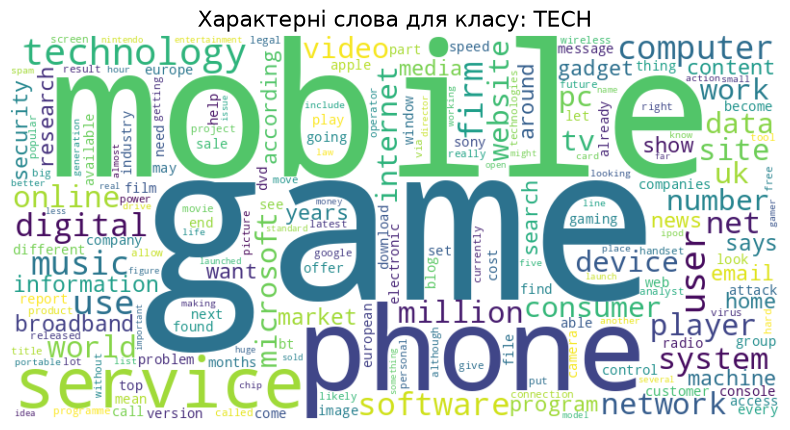

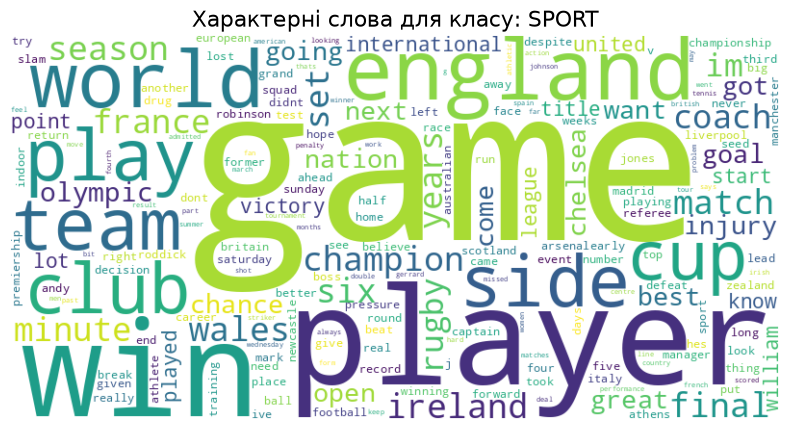

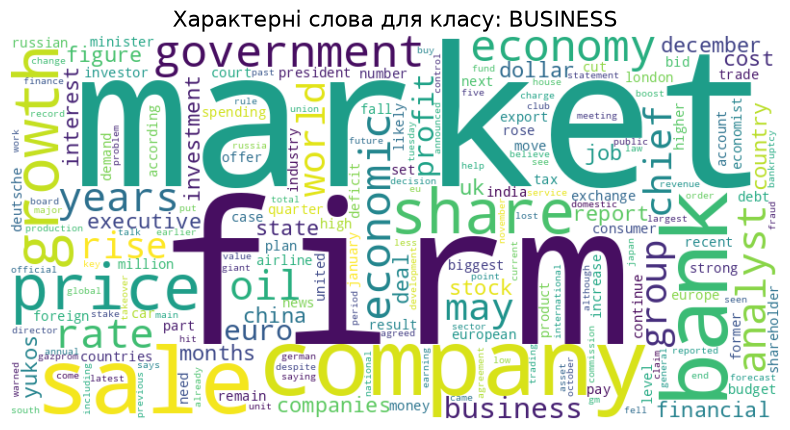

In [6]:
# 3 WordCloud
for category in target_classes:
    text_data = ' '.join(df[df['category'] == category]['clean_content'])
    
    wordcloud = WordCloud(width=800, height=400, background_color='white', collocations=False).generate(text_data)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f'Характерні слова для класу: {category.upper()}', fontsize=16)
    plt.axis('off')
    plt.show()

In [7]:
# 4 TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(df['clean_content'])
y = df['category']

# 5 НАВЧАННЯ
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#  алгоритм Наївного Байєса
model = MultinomialNB()
model.fit(X_train, y_train)

# Робимо передбачення на тестовій вибірці
y_pred = model.predict(X_test)

# Виводимо метрики якості
print("\n--- Результати класифікації ---")
print(f"Accuracy (Загальна точність): {accuracy_score(y_test, y_pred):.4f}\n")
print("Детальний звіт (Precision, Recall, F1-score):")
print(classification_report(y_test, y_pred))


--- Результати класифікації ---
Accuracy (Загальна точність): 0.9965

Детальний звіт (Precision, Recall, F1-score):
              precision    recall  f1-score   support

    business       0.99      1.00      1.00       103
       sport       1.00      1.00      1.00        98
        tech       1.00      0.99      0.99        84

    accuracy                           1.00       285
   macro avg       1.00      1.00      1.00       285
weighted avg       1.00      1.00      1.00       285

